# 02 · Z-stack Fusion — one sharp image from many focal planes

**Problem.** Tissue is not flat. With a single focal plane, parts of every field of view are out of focus —
especially for thick sections, cytology and microbiology slides. Volumetric scanners capture a **z-stack** and fuse
the sharpest pixels into one all-in-focus image.

**Approach.** We *simulate* the optics so there is a perfect ground truth:
`defocus radius(x, y) = blur_per_z × |z_plane − tissue_height(x, y)|`, rendered with a disk point-spread function.
Then we compare:

| Method | Idea |
|---|---|
| Best single plane | what a single-plane scanner keeps (baseline) |
| Focus selection | per-pixel argmax of a local Sum-Modified-Laplacian focus measure → also yields a **depth map** |
| Laplacian pyramid | multi-scale: keep the strongest detail coefficient at every scale |

In [ ]:
# --- setup: works locally (run from repo root or notebooks/) and on Google Colab ---
import os, sys
if "google.colab" in sys.modules and not os.path.exists("wsi-smart-scan"):
    !git clone https://github.com/DPK516/wsi-smart-scan.git
    %cd wsi-smart-scan
    !pip -q install -r requirements.txt
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("results", exist_ok=True); os.makedirs("models", exist_ok=True); os.makedirs("assets", exist_ok=True)

In [2]:
from skimage import data
from src.fusion import (depth_surface, make_zstack, fuse_focus_selection, fuse_laplacian_pyramid,
                        best_single_plane, image_quality, depth_error, compare_methods)
from src.utils import to_uint8
tissue = data.immunohistochemistry()

## 1 · A simulated z-stack

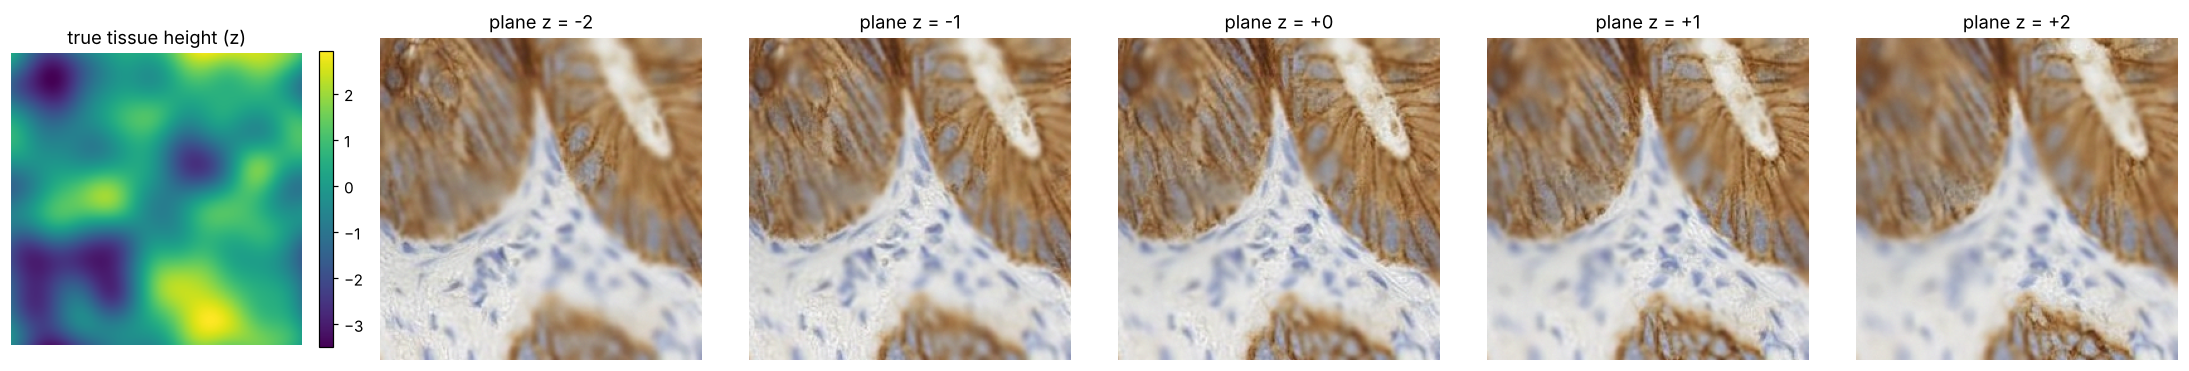

In [3]:
tile = tissue[100:356, 150:406]
z = np.arange(5, dtype=np.float32) - 2
depth = depth_surface(tile.shape, seed=3); depth -= np.median(depth)
stack = make_zstack(tile, depth, z, seed=3)

fig, ax = plt.subplots(1, 6, figsize=(20, 3.6))
im = ax[0].imshow(depth, cmap="viridis"); ax[0].set_title("true tissue height (z)"); fig.colorbar(im, ax=ax[0], fraction=0.046)
for i in range(5):
    ax[i + 1].imshow(stack[i]); ax[i + 1].set_title(f"plane z = {z[i]:+.0f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("assets/zstack_planes.png", dpi=110, bbox_inches="tight"); plt.show()

## 2 · Fuse it

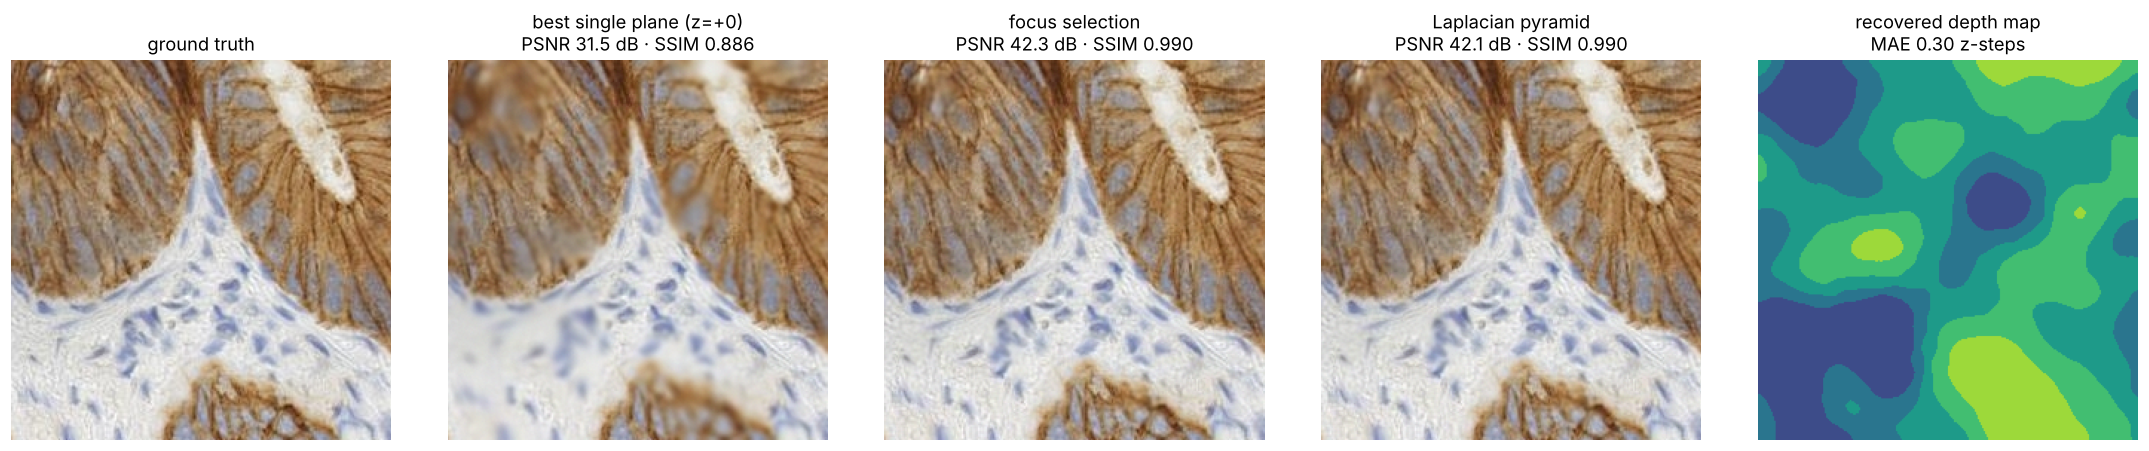

In [4]:
single, k = best_single_plane(stack)
sel, idx = fuse_focus_selection(stack)
pyr = fuse_laplacian_pyramid(stack)

fig, ax = plt.subplots(1, 5, figsize=(20, 4))
panels = [(tile, "ground truth"), (single, f"best single plane (z={z[k]:+.0f})"), (sel, "focus selection"),
          (pyr, "Laplacian pyramid")]
for a, (im, t) in zip(ax, panels):
    q = "" if t == "ground truth" else f"\nPSNR {image_quality(im, tile)['psnr']:.1f} dB · SSIM {image_quality(im, tile)['ssim']:.3f}"
    a.imshow(im); a.set_title(t + q); a.axis("off")
ax[4].imshow(z[idx], cmap="viridis", vmin=depth.min(), vmax=depth.max()); ax[4].axis("off")
ax[4].set_title(f"recovered depth map\nMAE {depth_error(idx, z, depth):.2f} z-steps")
plt.tight_layout(); plt.savefig("assets/fusion_methods.png", dpi=110, bbox_inches="tight"); plt.show()

## 3 · Benchmark: 16 tissue tiles × number of focal planes

In [5]:
rows = []
for n_planes in [3, 5, 7]:
    seed = 0
    for y in range(0, 512, 128):
        for x in range(0, 512, 128):
            r = compare_methods(tissue[y:y+128, x:x+128], n_planes=n_planes, seed=seed); seed += 1
            for method, m in r.items():
                rows.append({"planes": n_planes, "method": method, **m})
bench = pd.DataFrame(rows)
table = bench.groupby(["planes", "method"])[["psnr", "ssim", "depth_mae"]].agg(["mean", "std"]).round(3)
bench.to_csv("results/fusion_benchmark.csv", index=False)
table

psnr          ssim        depth_mae       
                            mean    std   mean    std      mean    std
planes method                                                         
3      focus_selection    36.396  2.614  0.958  0.022     0.564  0.156
       laplacian_pyramid  36.315  2.587  0.957  0.022       NaN    NaN
       single_best_plane  30.924  1.653  0.870  0.037       NaN    NaN
5      focus_selection    41.616  2.576  0.986  0.010     0.339  0.090
       laplacian_pyramid  41.455  2.532  0.986  0.010       NaN    NaN
       single_best_plane  30.922  1.652  0.870  0.038       NaN    NaN
7      focus_selection    44.198  1.192  0.993  0.003     0.290  0.089
       laplacian_pyramid  43.893  1.188  0.992  0.003       NaN    NaN
       single_best_plane  30.921  1.655  0.870  0.038       NaN    NaN

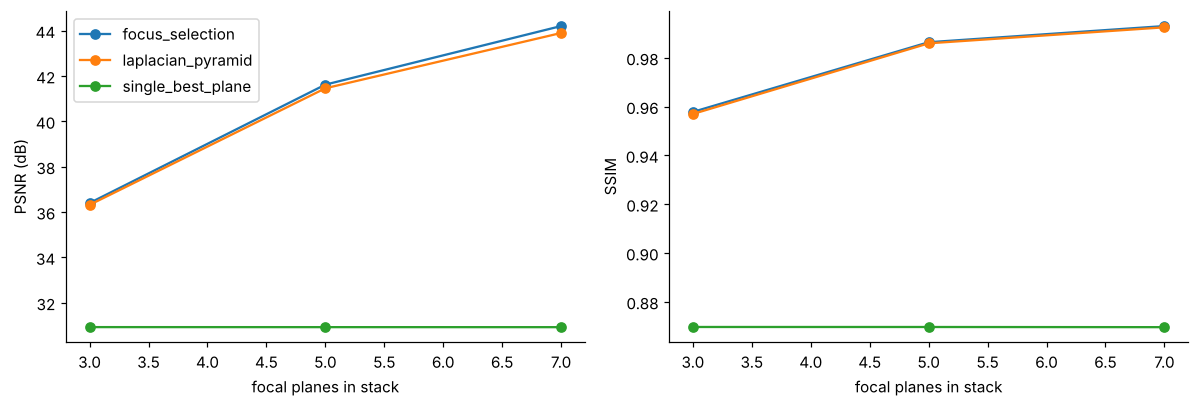

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for method, g in bench.groupby("method"):
    s = g.groupby("planes")[["psnr", "ssim"]].mean()
    ax[0].plot(s.index, s.psnr, marker="o", label=method); ax[1].plot(s.index, s.ssim, marker="o", label=method)
ax[0].set(xlabel="focal planes in stack", ylabel="PSNR (dB)"); ax[1].set(xlabel="focal planes in stack", ylabel="SSIM")
ax[0].legend(); plt.tight_layout(); plt.savefig("assets/fusion_vs_planes.png", dpi=120); plt.show()

## 4 · Speed (CPU)

In [7]:
tile = tissue[:256, :256]; z = np.arange(5, dtype=np.float32) - 2
stack = make_zstack(tile, depth_surface(tile.shape, seed=0), z)
for name, fn in [("best_single_plane", best_single_plane), ("focus_selection", fuse_focus_selection),
                 ("laplacian_pyramid", fuse_laplacian_pyramid)]:
    t0 = time.perf_counter()
    for _ in range(10): fn(stack)
    print(f"{name:18s} {(time.perf_counter() - t0) / 10 * 1000:7.1f} ms per 256×256 tile, 5 planes")

best_single_plane      0.9 ms per 256×256 tile, 5 planes
focus_selection       14.2 ms per 256×256 tile, 5 planes


laplacian_pyramid      9.2 ms per 256×256 tile, 5 planes


## 5 · Full smart-scan pipeline on held-out simulated slides

Tissue detection → per-tile autofocus (with an injected autofocus failure) → z-stack → fusion → focus QC.
The QC threshold was chosen on seeds 0–3; **seeds 10–19 are held out**.

In [8]:
from src.pipeline import SmartScanner, ScanConfig, demo_slide, benchmark_seeds
res = benchmark_seeds(range(10, 20), "results")
pd.Series(res["summary"]).round(3)

tissue_tiles         74.300
psnr_single          38.824
psnr_fused           47.474
ssim_single           0.978
ssim_fused            0.996
af_failures           5.600
detected              5.500
false_alarms          0.900
storage_saved_pct    86.120
depth_mae             0.370
ms_per_tile           1.657
detection_rate        0.982
false_alarm_rate      0.013
dtype: float64

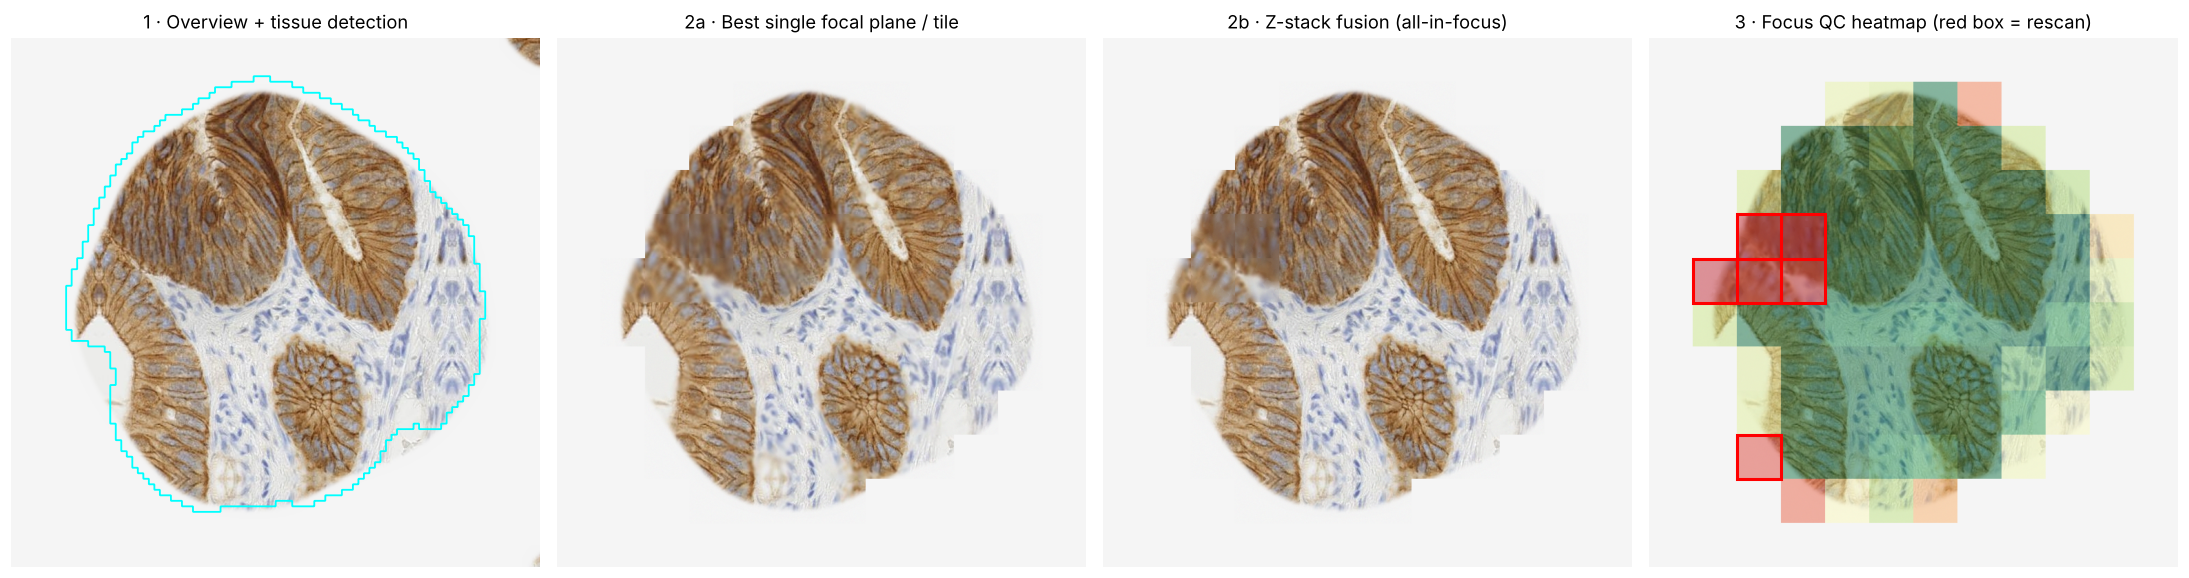

In [9]:
scanner = SmartScanner(ScanConfig(seed=11))
report = scanner.run(demo_slide(seed=11))
scanner.save_figures("assets")
json.dump(report, open("results/demo_scan_report.json", "w"), indent=2)
from IPython.display import Image, display
display(Image("assets/pipeline_overview.png"))